In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
df = pd.read_csv("Housing.csv")

In [7]:
print(df.head())

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


In [12]:
print(df.columns)

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')


In [13]:
X = df[['area']]
y = df['price']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [15]:
simple_model = LinearRegression()

In [16]:
simple_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [17]:
y_pred = simple_model.predict(X_test)

In [18]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

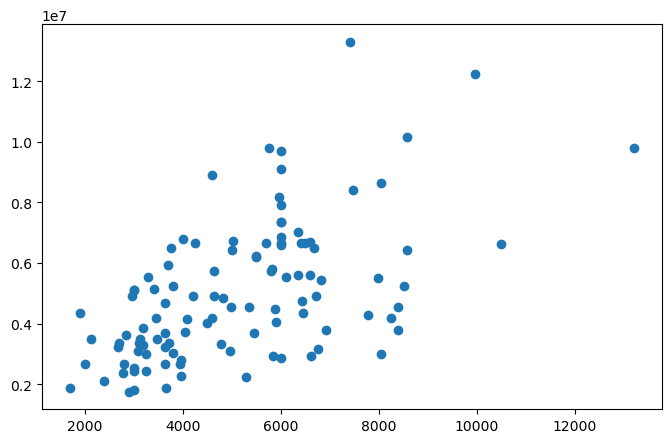

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test['area'],
    y_test,
    label="Actual Data"
)

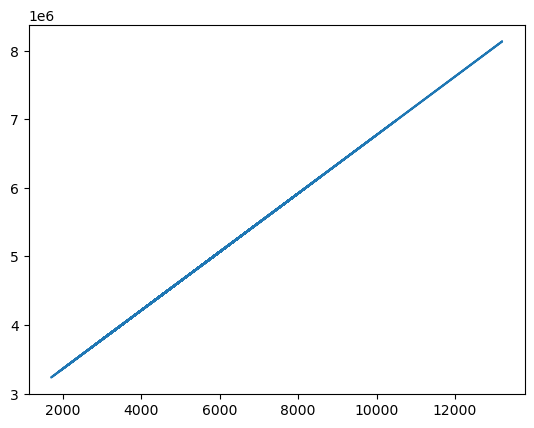

In [20]:
plt.plot(
    X_test['area'],
    y_pred,
    label="Regression Line"
)

C:\Users\pandi\AppData\Local\Temp\ipykernel_16168\4113562574.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


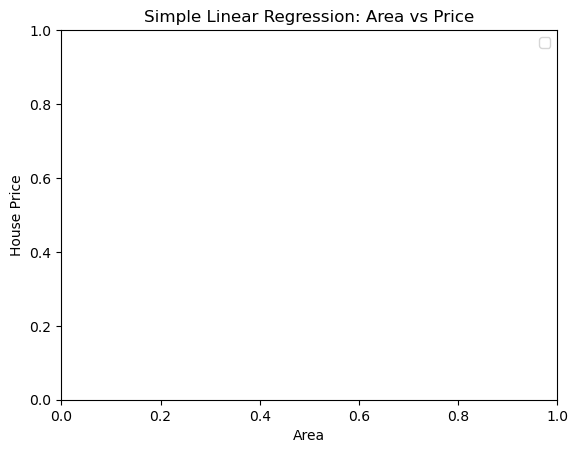

In [21]:
plt.xlabel("Area")
plt.ylabel("House Price")
plt.title("Simple Linear Regression: Area vs Price")
plt.legend()
plt.show()


In [22]:
X = df[
    [
        'area',
        'bedrooms',
        'bathrooms',
        'stories',
        'parking'
    ]
]

y = df['price']


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [25]:
multiple_model = LinearRegression()


In [26]:
multiple_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
y_pred = multiple_model.predict(X_test)

In [28]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [29]:
print("MAE:", mae)
print("MSE:", mse)
print("R² Score:", r2)

MAE: 1127483.3523235186
MSE: 2292721545725.3623
R² Score: 0.5464062355495871


In [30]:
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(feature, ":", coefficient)

area : 308.86695608764126
bedrooms : 151246.75062952162
bathrooms : 1185731.7137011937
stories : 495100.7626617587
parking : 337660.8302982581


In [31]:
print("Intercept:", multiple_model.intercept_)

Intercept: 51999.67680883594
